# BÀI LAB: XỬ LÝ VIDEO - HIỂN THỊ VIDEO VÀ TÍNH FPS TRÊN GOOGLE COLAB

### PHẦN 1: THIẾT LẬP MÔI TRƯỜNG VÀ KẾT NỐI GOOGLE DRIVE

In [16]:
import cv2
import time
from google.colab import drive
import os
import matplotlib.pyplot as plt
from IPython.display import clear_output

# Mount Google Drive để truy cập file video
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### PHẦN 2: KIỂM TRA VÀ ĐỌC VIDEO TỪ GOOGLE DRIVE

In [17]:
# Kiểm tra file có tồn tại không
video_path = '/content/drive/MyDrive/data/pexels-ahmed-18338415.mp4'
if os.path.exists(video_path):
    print(f"File video được tìm thấy: {video_path}")
    print(f"Kích thước file: {os.path.getsize(video_path)} bytes")
else:
    print("Không tìm thấy file video. Vui lòng kiểm tra đường dẫn.")
    print("Đường dẫn hiện tại đang tìm:", video_path)

# Đọc video từ file trên Google Drive
my_video = cv2.VideoCapture('/content/drive/MyDrive/data/pexels-ahmed-18338415.mp4')

File video được tìm thấy: /content/drive/MyDrive/data/pexels-ahmed-18338415.mp4
Kích thước file: 12484844 bytes


In [18]:
# Kiểm tra video có mở được không
if my_video.isOpened():
    # Lấy thông tin video
    fps_original = my_video.get(cv2.CAP_PROP_FPS)
    width = int(my_video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(my_video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(my_video.get(cv2.CAP_PROP_FRAME_COUNT))
    duration = total_frames / fps_original

    print("THÔNG TIN VIDEO:")
    print(f"- FPS gốc: {fps_original:.2f}")
    print(f"- Kích thước: {width}x{height}")
    print(f"- Tổng số frame: {total_frames}")
    print(f"- Thời lượng: {duration:.2f} giây")
else:
    print("Lỗi: Không thể mở video!")

THÔNG TIN VIDEO:
- FPS gốc: 60.00
- Kích thước: 3840x2160
- Tổng số frame: 301
- Thời lượng: 5.02 giây


### PHẦN 3: THIẾT LẬP FONT CHO TEXT
*(Phần này định nghĩa font chữ dùng cho video)*

In [19]:
# Ghi text trên hình ảnh
font = cv2.FONT_HERSHEY_SIMPLEX
font_color = (255, 255, 255)
font_scale = 2
font_thicknes = 2

print("Cấu hình font:")
print(f"- Font: {font}")
print(f"- Màu (BGR): {font_color}")
print(f"- Kích thước: {font_scale}")
print(f"- Độ dày: {font_thicknes}")

Cấu hình font:
- Font: 0
- Màu (BGR): (255, 255, 255)
- Kích thước: 2
- Độ dày: 2


### PHẦN 4: VÒNG LẶP HIỂN THỊ VIDEO

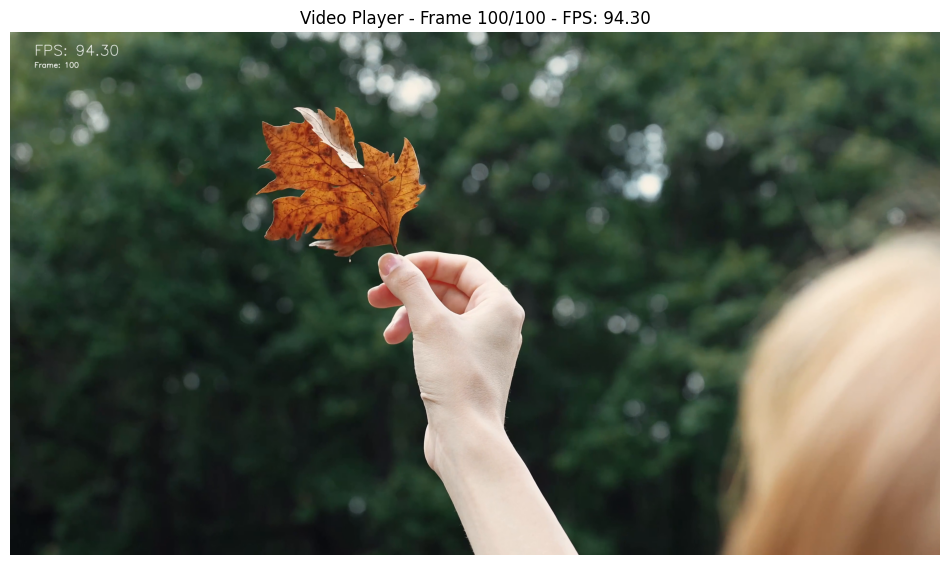


Đã hiển thị 100 frame


In [20]:
# Thiết lập cho hiển thị video
frame_count = 0
max_frames = 100  # Giới hạn số frame để demo (tránh quá tải)
fps_list = []  # Lưu trữ FPS để tính trung bình

print("Bắt đầu phát video...")
print(f"Sẽ hiển thị tối đa {max_frames} frame")

# Hiển thị từng khung ảnh
while frame_count < max_frames:
    # Thời gian trước khi đọc
    start_time = time.time()

    # Đọc 1 frame
    ret, frame = my_video.read()

    # Thoát khi không thể đọc được frame
    if not ret:
        print("Đã đọc hết video hoặc gặp lỗi")
        break

    # Thời gian sau khi đọc
    end_time = time.time()

    # Tính FPS:
    fps = 1/(end_time-start_time)
    fps_list.append(fps)

    # Ghi số lượng fps (Sử dụng biến font từ Phần 3)
    cv2.putText(frame, f'FPS: {fps:.2f}', (100, 100), font, font_scale, font_color , font_thicknes)
    # Ghi số frame hiện tại
    cv2.putText(frame, f'Frame: {frame_count + 1}', (100, 150), font, 1, font_color, 2)

    # Chuyển BGR sang RGB cho matplotlib
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Hiển thị frame bằng matplotlib
    clear_output(wait=True)
    plt.figure(figsize=(12, 8))
    plt.imshow(frame_rgb)
    plt.title(f'Video Player - Frame {frame_count + 1}/{max_frames} - FPS: {fps:.2f}')
    plt.axis('off')
    plt.show()

    frame_count += 1

    # Delay để điều khiển tốc độ phát (thay cho cv2.waitKey)
    time.sleep(0.1)  # 100ms delay

print(f"\nĐã hiển thị {frame_count} frame")

### PHẦN 5: THỐNG KÊ VÀ GIẢI PHÓNG TÀI NGUYÊN

In [21]:
# Hủy bỏ player
my_video.release()

# Tính toán thống kê FPS
if fps_list:
    avg_fps = sum(fps_list) / len(fps_list)
    max_fps = max(fps_list)
    min_fps = min(fps_list)

    print("="*50)
    print("THỐNG KÊ VIDEO PROCESSING")
    print("="*50)
    print(f"Tổng số frame đã xử lý: {frame_count}")
    print(f"FPS trung bình: {avg_fps:.2f}")
    print(f"FPS cao nhất: {max_fps:.2f}")
    print(f"FPS thấp nhất: {min_fps:.2f}")
    print(f"Thời gian xử lý trung bình mỗi frame: {1000/avg_fps:.2f} ms")
else:
    print("Không có dữ liệu FPS để thống kê")

print("\nVideo player đã kết thúc!")
print("Tài nguyên đã được giải phóng.")

THỐNG KÊ VIDEO PROCESSING
Tổng số frame đã xử lý: 100
FPS trung bình: 81.14
FPS cao nhất: 95.15
FPS thấp nhất: 5.20
Thời gian xử lý trung bình mỗi frame: 12.32 ms

Video player đã kết thúc!
Tài nguyên đã được giải phóng.


### LƯU FRAMES VÀO GOOGLE DRIVE

In [22]:
def save_frames_to_drive(video_path, drive_folder='Colab_Frames', max_frames=30, quality=95):
    if not os.path.exists('/content/drive'):
        print("🔗 Đang kết nối Google Drive...")
        drive.mount('/content/drive')

    drive_path = f'/content/drive/MyDrive/{drive_folder}'
    if not os.path.exists(drive_path):
        os.makedirs(drive_path)

    video = cv2.VideoCapture(video_path)
    if not video.isOpened():
        print("Lỗi: Không thể mở video!")
        return

    font = cv2.FONT_HERSHEY_SIMPLEX
    font_color = (255, 255, 255)

    frame_count = 0
    saved_count = 0

    while frame_count < max_frames:
        start_time = time.time()
        ret, frame = video.read()

        if not ret:
            break

        end_time = time.time()
        fps = 1/(end_time-start_time)

        cv2.putText(frame, f'Frame: {frame_count + 1}', (10, 30), font, 0.8, font_color, 2)
        cv2.putText(frame, f'FPS: {fps:.1f}', (10, 60), font, 0.8, font_color, 2)

        timestamp = time.strftime("%Y%m%d_%H%M%S")
        filename = f"frame_{frame_count + 1:04d}_{timestamp}.jpg"
        filepath = os.path.join(drive_path, filename)

        success = cv2.imwrite(filepath, frame, [cv2.IMWRITE_JPEG_QUALITY, quality])
        if success:
            saved_count += 1
        frame_count += 1

    video.release()
    print(f"Đã lưu: {saved_count} frames vào {drive_path}")

# Sử dụng
video_path = '/content/drive/MyDrive/data/pexels-ahmed-18338415.mp4'
save_frames_to_drive(video_path, drive_folder='Video_Frames', max_frames=5)

Đã lưu: 5 frames vào /content/drive/MyDrive/Video_Frames
